In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('energydata_complete.csv')

In [3]:
df.head()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [4]:
df.shape

(19735, 29)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  str    
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null  float64
 19  T9           19

In [6]:
df.isnull().sum()

date           0
Appliances     0
lights         0
T1             0
RH_1           0
T2             0
RH_2           0
T3             0
RH_3           0
T4             0
RH_4           0
T5             0
RH_5           0
T6             0
RH_6           0
T7             0
RH_7           0
T8             0
RH_8           0
T9             0
RH_9           0
T_out          0
Press_mm_hg    0
RH_out         0
Windspeed      0
Visibility     0
Tdewpoint      0
rv1            0
rv2            0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [9]:
print("Mean :",df['Appliances'].mean())
print('Median :',df['Appliances'].median())
print('Mode :',df['Appliances'].mode())

Mean : 97.6949581960983
Median : 60.0
Mode : 0    50
Name: Appliances, dtype: int64


In [12]:
print("Variance :",df['Appliances'].var())

Variance : 10511.353179707132


In [13]:
print("Standard Deviation :",df['Appliances'].std())

Standard Deviation : 102.52489053740624


In [16]:
min_value = df['Appliances'].min()
max_value = df['Appliances'].max()
range_ = max_value - min_value 

print("Min value :",min_value)
print('Max Value :', max_value)
print('Range :',range_)

Min value : 10
Max Value : 1080
Range : 1070


In [19]:
print("Skewness :",df['Appliances'].skew())
print('Kurtosis :',df['Appliances'].kurt())

Skewness : 3.3863672147430623
Kurtosis : 13.667863286939872


Quartiles & IQR

In [22]:
Q1 = np.percentile(df['Appliances'], 25)  # using numpy
Q3 = df['Appliances'].quantile(0.75)  # using pandas 
IQR = Q3 - Q1

In [23]:
print(Q1)
print(Q3)
print(IQR)

50.0
100.0
50.0


In [24]:
Lf = Q1 - (1.5 * IQR)
Uf = Q3 + (1.5 * IQR)

In [25]:
print(Lf)
print(Uf)

-25.0
175.0


In [32]:
def flag():
    count = (df['Appliances']> 175).sum()
    print(count)
    return count

flag()

2138


np.int64(2138)

<Axes: xlabel='Appliances', ylabel='Count'>

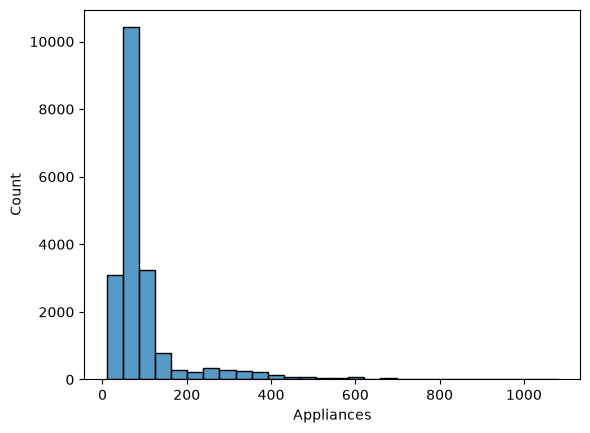

In [34]:
sns.histplot(df['Appliances'], bins = 28)

<Axes: xlabel='Appliances'>

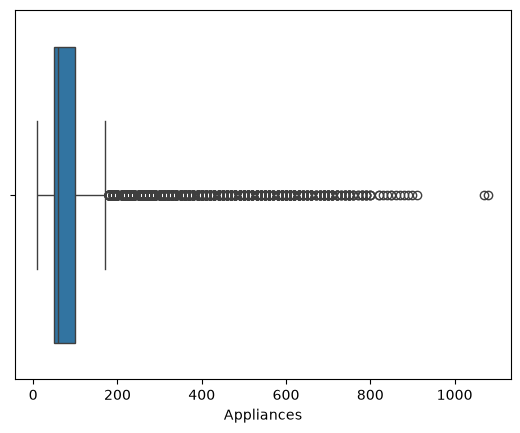

In [35]:
sns.boxplot(x= df['Appliances'])

<Axes: xlabel='Appliances', ylabel='Density'>

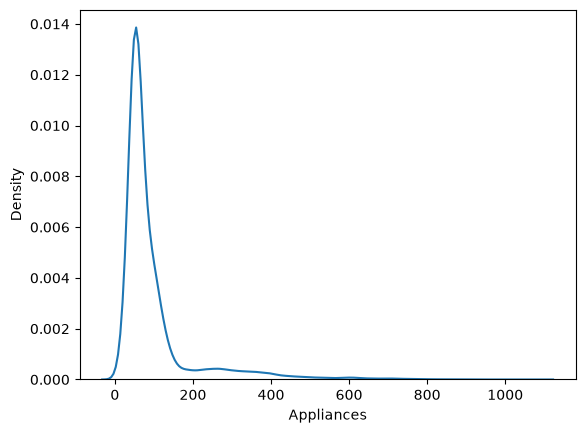

In [36]:
sns.kdeplot(x = df['Appliances'])